In [3]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from curl_cffi import requests
import yfinance as yf
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import talib as ta
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import pickle
from hmmlearn.hmm import GaussianHMM
import boto3
from dotenv import load_dotenv
import os
import seaborn as sns
sns.set_theme(style="whitegrid")
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from tqdm import tqdm

In [4]:
with open('/Users/gautamnaik/Developer/ai/gmmm_direction_prediction/data/nifty_data.pkl', 'rb') as f:
    data = pickle.load(f)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4418 entries, 2007-09-17 00:00:00+05:30 to 2025-09-19 00:00:00+05:30
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          4418 non-null   float64
 1   High          4418 non-null   float64
 2   Low           4418 non-null   float64
 3   Close         4418 non-null   float64
 4   Volume        4418 non-null   int64  
 5   Dividends     4418 non-null   float64
 6   Stock Splits  4418 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 276.1 KB


In [6]:
df= data.copy()

In [7]:
df

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2007-09-17 00:00:00+05:30,4518.450195,4549.049805,4482.850098,4494.649902,0,0.0,0.0
2007-09-18 00:00:00+05:30,4494.100098,4551.799805,4481.549805,4546.200195,0,0.0,0.0
2007-09-19 00:00:00+05:30,4550.250000,4739.000000,4550.250000,4732.350098,0,0.0,0.0
2007-09-20 00:00:00+05:30,4734.850098,4760.850098,4721.149902,4747.549805,0,0.0,0.0
2007-09-21 00:00:00+05:30,4752.950195,4855.700195,4733.700195,4837.549805,0,0.0,0.0
...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,25118.900391,25138.449219,25048.750000,25069.199219,185400,0.0,0.0
2025-09-16 00:00:00+05:30,25073.599609,25261.400391,25070.449219,25239.099609,240100,0.0,0.0
2025-09-17 00:00:00+05:30,25276.599609,25346.500000,25275.349609,25330.250000,268900,0.0,0.0


In [8]:
df['return_1d'] = df['Close'].pct_change()
df['return_5d'] = df['Close'].pct_change(5)
df['momentum_10d'] = ta.MOM(df['Close'], timeperiod=10)
df['ma_ratio'] = df['Close'] / ta.SMA(df['Close'], timeperiod=50)

# Risk Features
df['vol_10d'] = df['return_1d'].rolling(10).std()
df['vol_20d'] = df['return_1d'].rolling(20).std()
df['vol_ratio'] = df['vol_10d'] / df['vol_20d']
df['atr_14'] = ta.ATR(df['High'], df['Low'], df['Close'], timeperiod=14) / df['Close']

# Stress Features
df['drawdown'] = df['Close'] / df['Close'].cummax() - 1

# Exhaustion Features
df['rsi_14'] = ta.RSI(df['Close'], timeperiod=14)

# Trend Strength Features
df['adx_14'] = ta.ADX(df['High'], df['Low'], df['Close'], timeperiod=14)

In [9]:
window = 252  # ~1 year of trading days
for col in ['return_1d', 'return_5d', 'momentum_10d', 'ma_ratio', 
            'vol_10d', 'vol_20d', 'vol_ratio', 'atr_14', 
            'drawdown', 'rsi_14', 'adx_14']:
    df[f'{col}_z'] = (df[col] - df[col].rolling(window).mean()) / df[col].rolling(window).std()

In [10]:
zscore_cols = [col for col in df.columns if col.endswith('_z')]

In [11]:
df

,Open,High,Low,Close,Volume,Dividends,Stock Splits,return_1d,return_5d,momentum_10d,...,return_5d_z,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z,adx_14_z
Date,,,,,,,,,,,,,,,,,,,,,
2007-09-17 00:00:00+05:30,4518.450195,4549.049805,4482.850098,4494.649902,0,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-09-18 00:00:00+05:30,4494.100098,4551.799805,4481.549805,4546.200195,0,0.0,0.0,0.011469,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-09-19 00:00:00+05:30,4550.250000,4739.000000,4550.250000,4732.350098,0,0.0,0.0,0.040946,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-09-20 00:00:00+05:30,4734.850098,4760.850098,4721.149902,4747.549805,0,0.0,0.0,0.003212,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-09-21 00:00:00+05:30,4752.950195,4855.700195,4733.700195,4837.549805,0,0.0,0.0,0.018957,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,25118.900391,25138.449219,25048.750000,25069.199219,185400,0.0,0.0,-0.001784,0.011950,444.148438,...,0.597368,0.736534,0.223451,-1.784797,-1.148942,-2.198674,-1.954375,0.818201,0.815694,-1.193261
2025-09-16 00:00:00+05:30,25073.599609,25261.400391,25070.449219,25239.099609,240100,0.0,0.0,0.006777,0.014898,659.500000,...,0.741292,1.078019,0.461394,-1.743319,-1.254367,-1.996493,-1.949217,1.001474,1.220401,-1.085975
2025-09-17 00:00:00+05:30,25276.599609,25346.500000,25275.349609,25330.250000,268900,0.0,0.0,0.003611,0.014301,615.199219,...,0.709718,1.002250,0.591904,-1.780614,-1.256610,-2.101944,-2.051370,1.107109,1.414710,-0.928202


In [12]:
features_orig = df[zscore_cols].dropna()

In [13]:
features_orig

,return_1d_z,return_5d_z,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z,adx_14_z
Date,,,,,,,,,,,
2008-12-05 00:00:00+05:30,-0.868366,-0.034404,0.818804,-0.893201,0.466628,0.875523,-0.442671,1.421776,-1.959277,-0.161185,-0.083382
2008-12-08 00:00:00+05:30,1.022532,0.851616,0.612411,-0.566939,0.135168,0.856711,-0.966425,1.300708,-1.868706,0.143849,-0.252925
2008-12-10 00:00:00+05:30,1.951083,1.918223,0.980275,0.009230,0.467282,0.987278,-0.576041,1.109375,-1.703545,0.703186,-0.379416
2008-12-11 00:00:00+05:30,-0.019707,1.859247,1.105420,0.063236,0.355722,0.715847,-0.419203,0.994198,-1.696675,0.668967,-0.493405
2008-12-12 00:00:00+05:30,0.098432,0.996233,0.820280,0.153577,0.229341,0.375358,-0.153147,0.944607,-1.681398,0.675594,-0.637009
...,...,...,...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,-0.220865,0.597368,0.736534,0.223451,-1.784797,-1.148942,-2.198674,-1.954375,0.818201,0.815694,-1.193261
2025-09-16 00:00:00+05:30,0.810716,0.741292,1.078019,0.461394,-1.743319,-1.254367,-1.996493,-1.949217,1.001474,1.220401,-1.085975
2025-09-17 00:00:00+05:30,0.438974,0.709718,1.002250,0.591904,-1.780614,-1.256610,-2.101944,-2.051370,1.107109,1.414710,-0.928202


In [14]:
features = features_orig.copy()

In [15]:
scaler = StandardScaler()
X = scaler.fit_transform(features)

In [16]:
best_bic = np.inf
best_model = None
clusters_count = None
for K in range(2, 8):
    for cov_type in ['full', 'tied', 'diag', 'spherical']:
        model = GaussianHMM(n_components=K, covariance_type=cov_type, n_iter=2000)
        model.fit(X)
        logL = model.score(X)
        n_params = K*(K-1) + K*X.shape[1]*2  # rough estimate
        bic = n_params * np.log(len(X)) - 2*logL
        if bic < best_bic:
            best_bic = bic
            best_model = model
            clusters_count = K

In [17]:
clusters_count

7

In [19]:
features['hmm_cluster'] = best_model.predict(X)

In [20]:
best_model.score(X)

-27395.16535925793

In [21]:
features

,return_1d_z,return_5d_z,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z,adx_14_z,hmm_cluster
Date,,,,,,,,,,,,
2008-12-05 00:00:00+05:30,-0.868366,-0.034404,0.818804,-0.893201,0.466628,0.875523,-0.442671,1.421776,-1.959277,-0.161185,-0.083382,3
2008-12-08 00:00:00+05:30,1.022532,0.851616,0.612411,-0.566939,0.135168,0.856711,-0.966425,1.300708,-1.868706,0.143849,-0.252925,3
2008-12-10 00:00:00+05:30,1.951083,1.918223,0.980275,0.009230,0.467282,0.987278,-0.576041,1.109375,-1.703545,0.703186,-0.379416,3
2008-12-11 00:00:00+05:30,-0.019707,1.859247,1.105420,0.063236,0.355722,0.715847,-0.419203,0.994198,-1.696675,0.668967,-0.493405,3
2008-12-12 00:00:00+05:30,0.098432,0.996233,0.820280,0.153577,0.229341,0.375358,-0.153147,0.944607,-1.681398,0.675594,-0.637009,5
...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,-0.220865,0.597368,0.736534,0.223451,-1.784797,-1.148942,-2.198674,-1.954375,0.818201,0.815694,-1.193261,1
2025-09-16 00:00:00+05:30,0.810716,0.741292,1.078019,0.461394,-1.743319,-1.254367,-1.996493,-1.949217,1.001474,1.220401,-1.085975,1
2025-09-17 00:00:00+05:30,0.438974,0.709718,1.002250,0.591904,-1.780614,-1.256610,-2.101944,-2.051370,1.107109,1.414710,-0.928202,1


In [22]:
df_merged = df.join(features["hmm_cluster" ], how='right')

In [23]:
df_merged

,Open,High,Low,Close,Volume,Dividends,Stock Splits,return_1d,return_5d,momentum_10d,...,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z,adx_14_z,hmm_cluster
Date,,,,,,,,,,,,,,,,,,,,,
2008-12-05 00:00:00+05:30,2786.649902,2821.149902,2701.350098,2714.399902,0,0.0,0.0,-0.026399,-0.014773,161.250000,...,0.818804,-0.893201,0.466628,0.875523,-0.442671,1.421776,-1.959277,-0.161185,-0.083382,3
2008-12-08 00:00:00+05:30,2714.699951,2861.550049,2714.699951,2784.000000,0,0.0,0.0,0.025641,0.037683,90.550049,...,0.612411,-0.566939,0.135168,0.856711,-0.966425,1.300708,-1.868706,0.143849,-0.252925,3
2008-12-10 00:00:00+05:30,2785.699951,2940.149902,2785.699951,2928.250000,0,0.0,0.0,0.051814,0.101757,220.000000,...,0.980275,0.009230,0.467282,0.987278,-0.576041,1.109375,-1.703545,0.703186,-0.379416,3
2008-12-11 00:00:00+05:30,2934.050049,2945.300049,2861.550049,2920.149902,0,0.0,0.0,-0.002766,0.099268,266.149902,...,1.105420,0.063236,0.355722,0.715847,-0.419203,0.994198,-1.696675,0.668967,-0.493405,3
2008-12-12 00:00:00+05:30,2915.350098,2936.800049,2812.550049,2921.350098,0,0.0,0.0,0.000411,0.047830,169.100098,...,0.820280,0.153577,0.229341,0.375358,-0.153147,0.944607,-1.681398,0.675594,-0.637009,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,25118.900391,25138.449219,25048.750000,25069.199219,185400,0.0,0.0,-0.001784,0.011950,444.148438,...,0.736534,0.223451,-1.784797,-1.148942,-2.198674,-1.954375,0.818201,0.815694,-1.193261,1
2025-09-16 00:00:00+05:30,25073.599609,25261.400391,25070.449219,25239.099609,240100,0.0,0.0,0.006777,0.014898,659.500000,...,1.078019,0.461394,-1.743319,-1.254367,-1.996493,-1.949217,1.001474,1.220401,-1.085975,1
2025-09-17 00:00:00+05:30,25276.599609,25346.500000,25275.349609,25330.250000,268900,0.0,0.0,0.003611,0.014301,615.199219,...,1.002250,0.591904,-1.780614,-1.256610,-2.101944,-2.051370,1.107109,1.414710,-0.928202,1


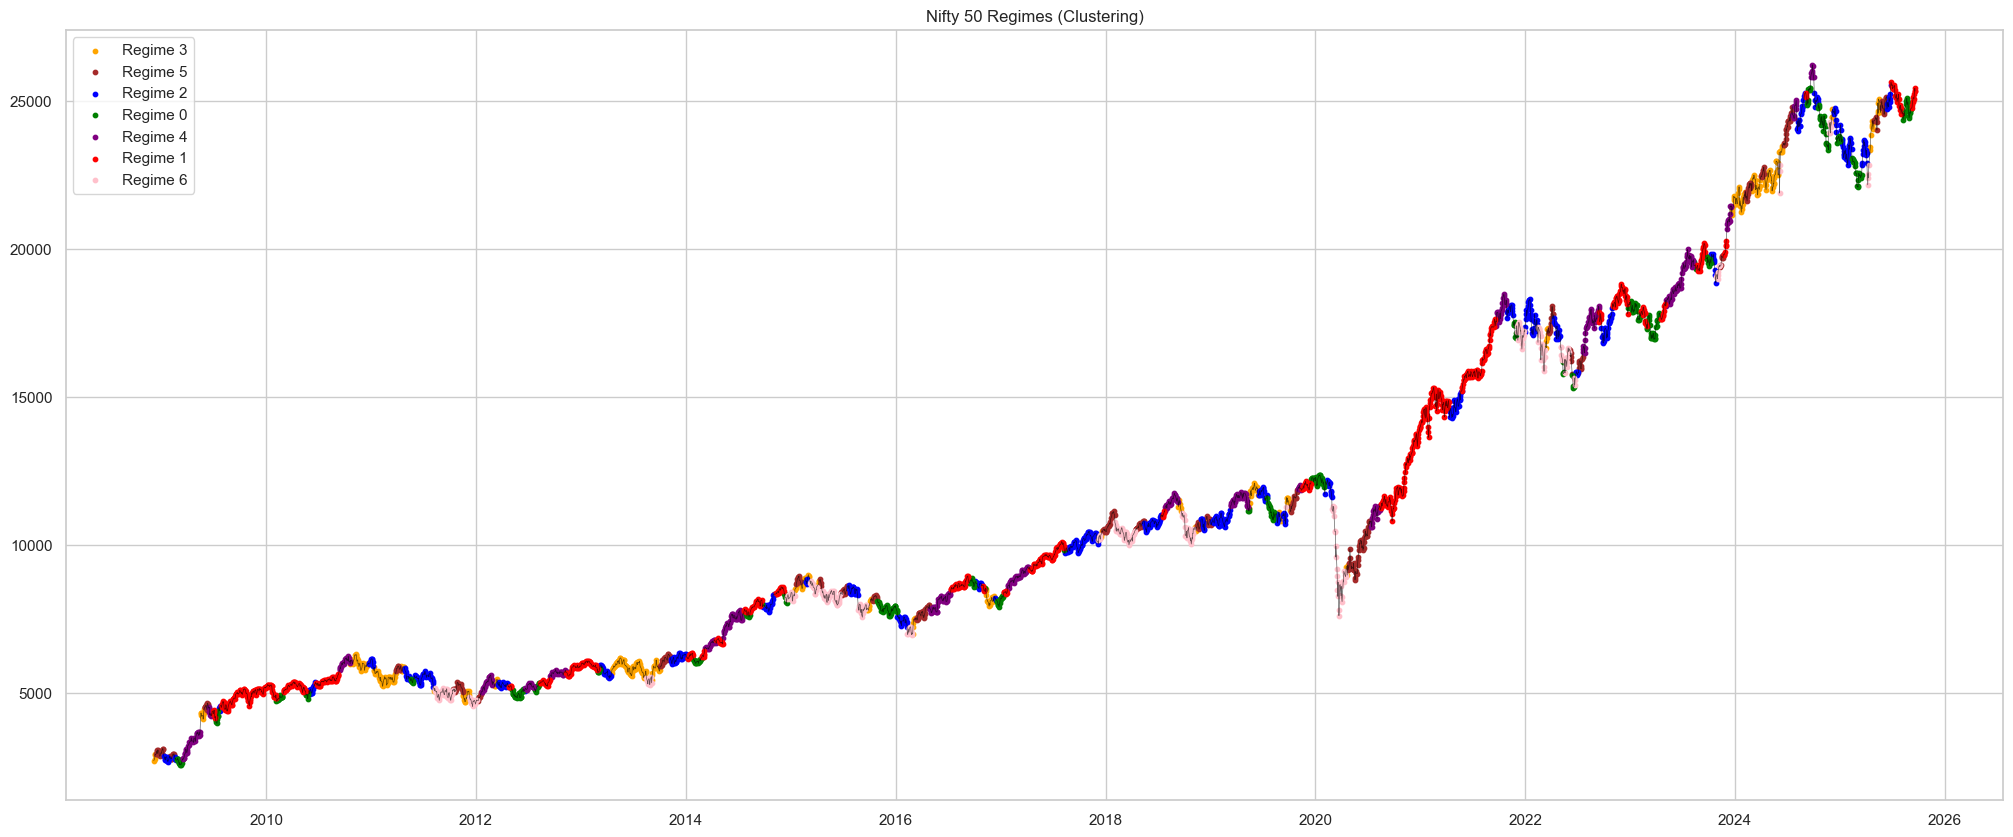

In [28]:
plt.figure(figsize=(25,10))
colors = {0:"green", 1:"red", 2:"blue", 3:"orange", 4:"purple", 5:"brown", 6:"pink", 7:"gray", 8:"cyan", 9:"magenta"}
for c in df_merged['hmm_cluster'].dropna().unique():
    mask = df_merged['hmm_cluster'] == c
    plt.scatter(df_merged.index[mask], df_merged['Close'][mask], label=f"Regime {c}", s=10, c=colors[c])
plt.plot(df_merged.index, df_merged['Close'], color='black', linewidth=0.5, alpha=0.6)
plt.title("Nifty 50 Regimes (Clustering)")
plt.legend()
# plt.xlim(df_merged.index[-1000], df_merged.index[-1])
plt.show()

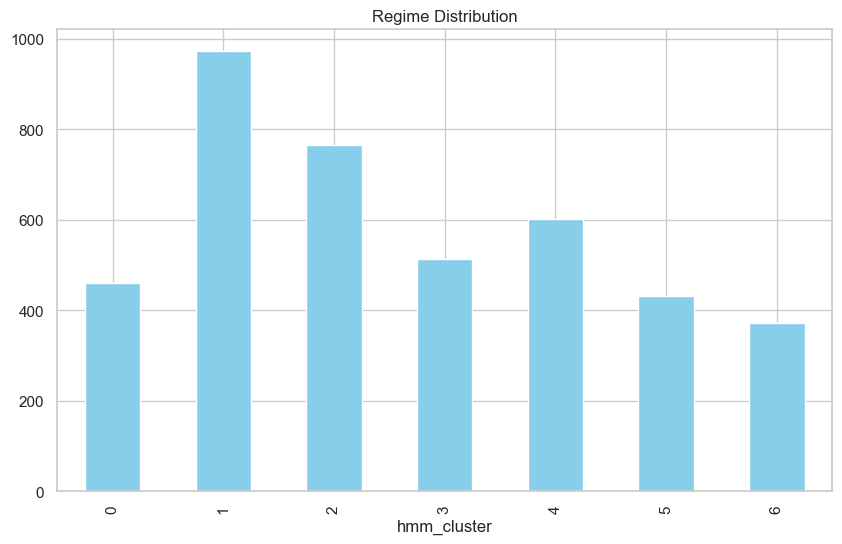

In [27]:
features['hmm_cluster'].value_counts().sort_index().plot(kind='bar', figsize=(10,6), color='skyblue')
plt.title("Regime Distribution");

In [29]:
features=features.drop("hmm_cluster", axis=1)

In [ ]:
def rolling_hmm_with_global_clustering(
    df, feature_cols, 
    n_states=7,              # local HMM states per window
    global_clusters=7,       # desired global regimes
    window=756,              # ~3 yrs of daily data
    refit_every=20,          # refit every month
    random_state=42
):
    X = df[feature_cols].dropna().values
    dates = df.dropna(subset=feature_cols).index
    n = len(X)

    # To store per-window results
    all_means = []          # local state means (for global clustering)
    all_state_segments = [] # (start_idx, end_idx, local_states)

    # Rolling HMM fits
    for i in tqdm(range(window, n, refit_every)):
        X_window = X[i-window:i]
        model = GaussianHMM(
            n_components=n_states, covariance_type="full",
            n_iter=300, random_state=random_state
        )
        model.fit(X_window)
        hidden_states = model.predict(X_window)

        # Store the means for global clustering
        all_means.append(model.means_)
        all_state_segments.append((i-window, i, hidden_states))

    # Stack all means (shape: total_windows * n_states, n_features)
    all_means_stack = np.vstack(all_means)

    # 🔹 Global clustering of all state means
    kmeans = KMeans(n_clusters=global_clusters, random_state=random_state)
    global_labels = kmeans.fit_predict(all_means_stack)

    # Map local → global IDs
    global_means = kmeans.cluster_centers_
    global_idx = 0
    all_regimes = pd.Series(index=dates, dtype=float)

    for (start, end, hidden_states), local_means in zip(all_state_segments, all_means):
        local_labels = global_labels[global_idx : global_idx + n_states]
        global_idx += n_states

        # Align local states to their assigned global cluster
        mapping = {r: local_labels[r] for r in range(n_states)}
        mapped_states = np.vectorize(mapping.get)(hidden_states)

        all_regimes.iloc[start:end] = mapped_states

    # Fill edges
    all_regimes = all_regimes.ffill().bfill()
    df["regime_id"] = all_regimes

    # Optional: store cluster centers for interpretation
    regime_summary = pd.DataFrame(global_means, columns=feature_cols)
    return df, regime_summary, kmeans

In [53]:
x_df = pd.DataFrame(X, index=features.index, columns=features.columns)
x_df

,return_1d_z,return_5d_z,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z,adx_14_z
Date,,,,,,,,,,,
2008-12-05 00:00:00+05:30,-0.866252,-0.021797,0.765944,-0.788761,0.460718,0.773978,-0.425122,1.265587,-1.506522,-0.173511,-0.057528
2008-12-08 00:00:00+05:30,1.034698,0.859853,0.571888,-0.488226,0.170922,0.758475,-0.937163,1.165946,-1.439163,0.116063,-0.214197
2008-12-10 00:00:00+05:30,1.968185,1.921200,0.917764,0.042511,0.461290,0.866076,-0.555509,1.008477,-1.316331,0.647052,-0.331083
2008-12-11 00:00:00+05:30,-0.013082,1.862515,1.035428,0.092258,0.363753,0.642387,-0.402179,0.913684,-1.311221,0.614567,-0.436415
2008-12-12 00:00:00+05:30,0.105685,1.003757,0.767332,0.175475,0.253258,0.361788,-0.142072,0.872870,-1.299860,0.620858,-0.569114
...,...,...,...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,-0.215308,0.606859,0.688592,0.239840,-1.507707,-0.894400,-2.141854,-1.513033,0.559122,0.753858,-1.083126
2025-09-16 00:00:00+05:30,0.821756,0.750073,1.009666,0.459021,-1.471443,-0.981282,-1.944194,-1.508787,0.695424,1.138053,-0.983987
2025-09-17 00:00:00+05:30,0.448037,0.718655,0.938425,0.579240,-1.504050,-0.983130,-2.047287,-1.592861,0.773986,1.322514,-0.838195


In [54]:
df_out, regime_summary, kmeans  = rolling_hmm_with_global_clustering(x_df, feature_cols=x_df.columns.tolist(), n_states=7, window=756, refit_every=20, global_clusters=7)

100%|██████████| 169/169 [00:19<00:00,  8.59it/s]


In [55]:
regime_summary

,return_1d_z,return_5d_z,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z,adx_14_z
0,0.171657,0.401654,0.477120,0.037984,0.601990,0.937374,-0.309303,0.750666,-0.259684,0.110343,-0.345260
1,-3.614928,-4.692432,-4.791955,-4.659181,4.764140,4.118326,1.475666,5.819392,-3.893967,-2.454757,2.864267
2,-0.050302,-0.386012,-0.815068,-1.467287,2.292799,2.175857,0.684633,2.148922,-1.493908,-1.006161,0.676979
3,0.108368,0.270223,0.466356,0.846499,-0.310701,-0.354835,-0.009847,-0.366937,0.532756,0.760300,0.660173
4,-0.126737,-0.396714,-0.607196,-0.901236,0.711654,0.740065,0.148182,0.860446,-0.866420,-0.828446,-0.041719
5,0.027323,0.074719,0.150014,0.269710,-0.653415,-0.714375,-0.115039,-0.747463,0.589193,0.301423,-0.033253
6,-0.042696,-0.120686,-0.175766,-0.127330,-0.093638,-0.140024,0.075056,-0.099368,-0.063806,-0.270628,-0.327148


In [56]:
df_out

,return_1d_z,return_5d_z,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z,adx_14_z,regime_id
Date,,,,,,,,,,,,
2008-12-05 00:00:00+05:30,-0.866252,-0.021797,0.765944,-0.788761,0.460718,0.773978,-0.425122,1.265587,-1.506522,-0.173511,-0.057528,0.0
2008-12-08 00:00:00+05:30,1.034698,0.859853,0.571888,-0.488226,0.170922,0.758475,-0.937163,1.165946,-1.439163,0.116063,-0.214197,0.0
2008-12-10 00:00:00+05:30,1.968185,1.921200,0.917764,0.042511,0.461290,0.866076,-0.555509,1.008477,-1.316331,0.647052,-0.331083,0.0
2008-12-11 00:00:00+05:30,-0.013082,1.862515,1.035428,0.092258,0.363753,0.642387,-0.402179,0.913684,-1.311221,0.614567,-0.436415,0.0
2008-12-12 00:00:00+05:30,0.105685,1.003757,0.767332,0.175475,0.253258,0.361788,-0.142072,0.872870,-1.299860,0.620858,-0.569114,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,-0.215308,0.606859,0.688592,0.239840,-1.507707,-0.894400,-2.141854,-1.513033,0.559122,0.753858,-1.083126,0.0
2025-09-16 00:00:00+05:30,0.821756,0.750073,1.009666,0.459021,-1.471443,-0.981282,-1.944194,-1.508787,0.695424,1.138053,-0.983987,0.0
2025-09-17 00:00:00+05:30,0.448037,0.718655,0.938425,0.579240,-1.504050,-0.983130,-2.047287,-1.592861,0.773986,1.322514,-0.838195,0.0


In [57]:
df_merged = df.join(df_out["regime_id" ], how='right')
df_merged

,Open,High,Low,Close,Volume,Dividends,Stock Splits,return_1d,return_5d,momentum_10d,...,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z,adx_14_z,regime_id
Date,,,,,,,,,,,,,,,,,,,,,
2008-12-05 00:00:00+05:30,2786.649902,2821.149902,2701.350098,2714.399902,0,0.0,0.0,-0.026399,-0.014773,161.250000,...,0.818804,-0.893201,0.466628,0.875523,-0.442671,1.421776,-1.959277,-0.161185,-0.083382,0.0
2008-12-08 00:00:00+05:30,2714.699951,2861.550049,2714.699951,2784.000000,0,0.0,0.0,0.025641,0.037683,90.550049,...,0.612411,-0.566939,0.135168,0.856711,-0.966425,1.300708,-1.868706,0.143849,-0.252925,0.0
2008-12-10 00:00:00+05:30,2785.699951,2940.149902,2785.699951,2928.250000,0,0.0,0.0,0.051814,0.101757,220.000000,...,0.980275,0.009230,0.467282,0.987278,-0.576041,1.109375,-1.703545,0.703186,-0.379416,0.0
2008-12-11 00:00:00+05:30,2934.050049,2945.300049,2861.550049,2920.149902,0,0.0,0.0,-0.002766,0.099268,266.149902,...,1.105420,0.063236,0.355722,0.715847,-0.419203,0.994198,-1.696675,0.668967,-0.493405,0.0
2008-12-12 00:00:00+05:30,2915.350098,2936.800049,2812.550049,2921.350098,0,0.0,0.0,0.000411,0.047830,169.100098,...,0.820280,0.153577,0.229341,0.375358,-0.153147,0.944607,-1.681398,0.675594,-0.637009,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,25118.900391,25138.449219,25048.750000,25069.199219,185400,0.0,0.0,-0.001784,0.011950,444.148438,...,0.736534,0.223451,-1.784797,-1.148942,-2.198674,-1.954375,0.818201,0.815694,-1.193261,0.0
2025-09-16 00:00:00+05:30,25073.599609,25261.400391,25070.449219,25239.099609,240100,0.0,0.0,0.006777,0.014898,659.500000,...,1.078019,0.461394,-1.743319,-1.254367,-1.996493,-1.949217,1.001474,1.220401,-1.085975,0.0
2025-09-17 00:00:00+05:30,25276.599609,25346.500000,25275.349609,25330.250000,268900,0.0,0.0,0.003611,0.014301,615.199219,...,1.002250,0.591904,-1.780614,-1.256610,-2.101944,-2.051370,1.107109,1.414710,-0.928202,0.0


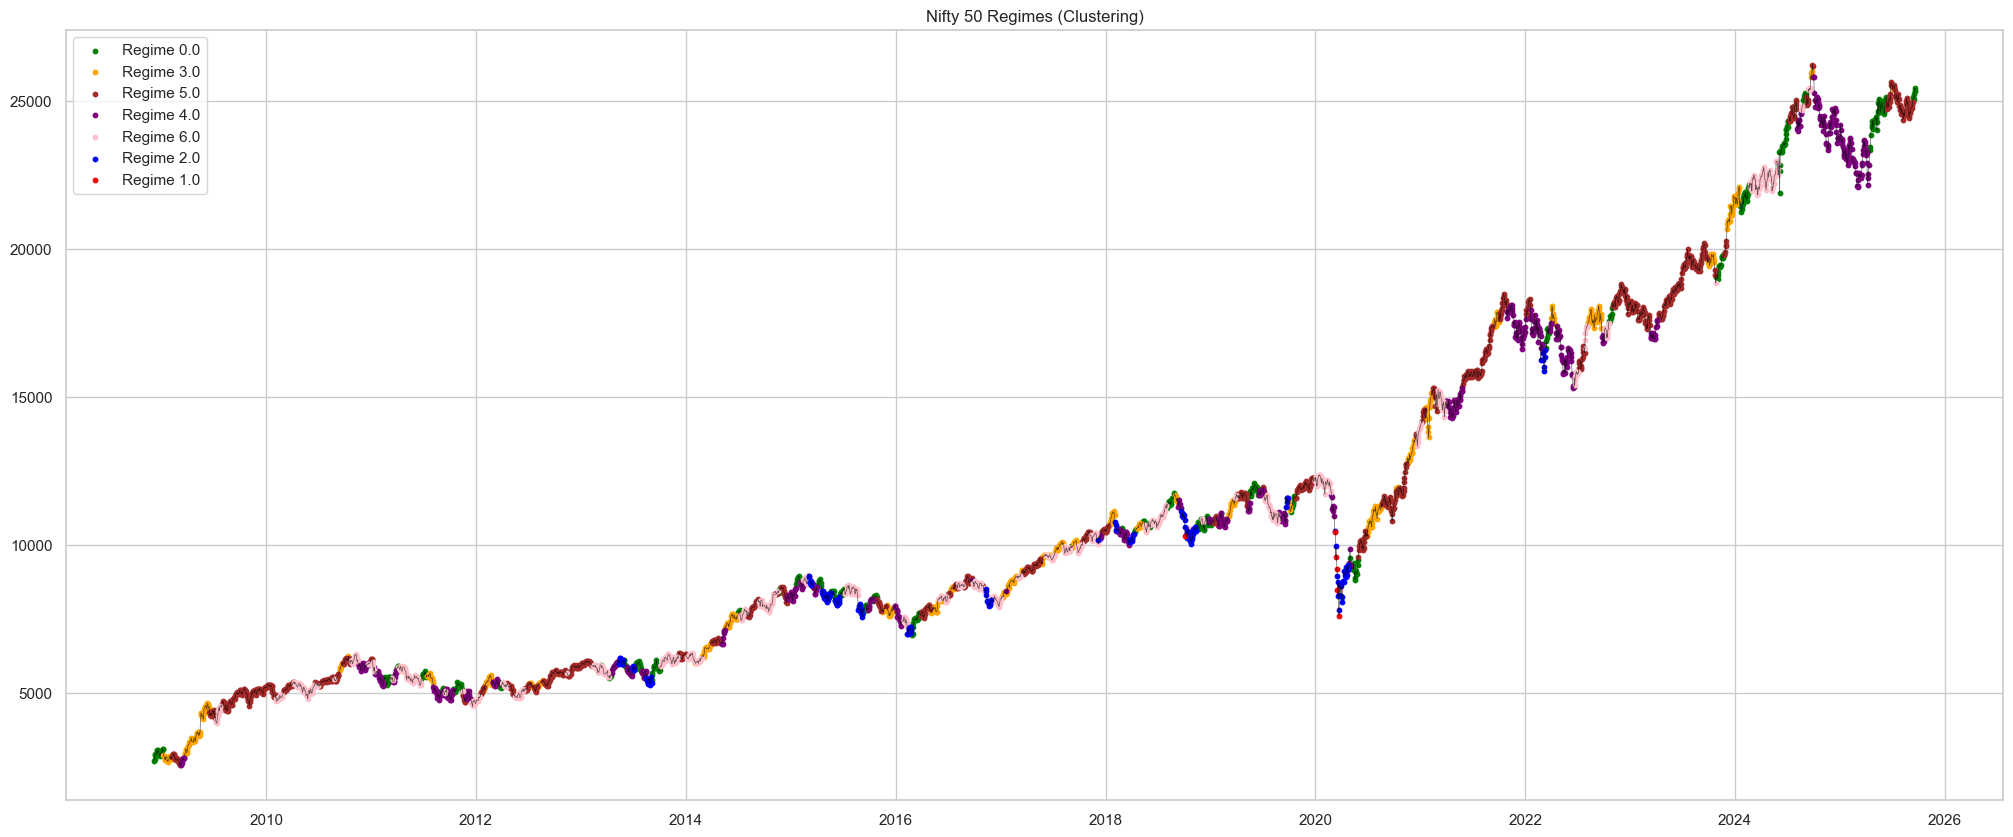

In [61]:
plt.figure(figsize=(25,10))
colors = {0:"green", 1:"red", 2:"blue", 3:"orange", 4:"purple", 5:"brown", 6:"pink", 7:"gray", 8:"cyan", 9:"magenta"}
for c in df_merged['regime_id'].dropna().unique():
    mask = df_merged['regime_id'] == c
    plt.scatter(df_merged.index[mask], df_merged['Close'][mask], label=f"Regime {c}", s=10, c=colors[c])
plt.plot(df_merged.index, df_merged['Close'], color='black', linewidth=0.5, alpha=0.6)
plt.title("Nifty 50 Regimes (Clustering)")
plt.legend()
plt.show()

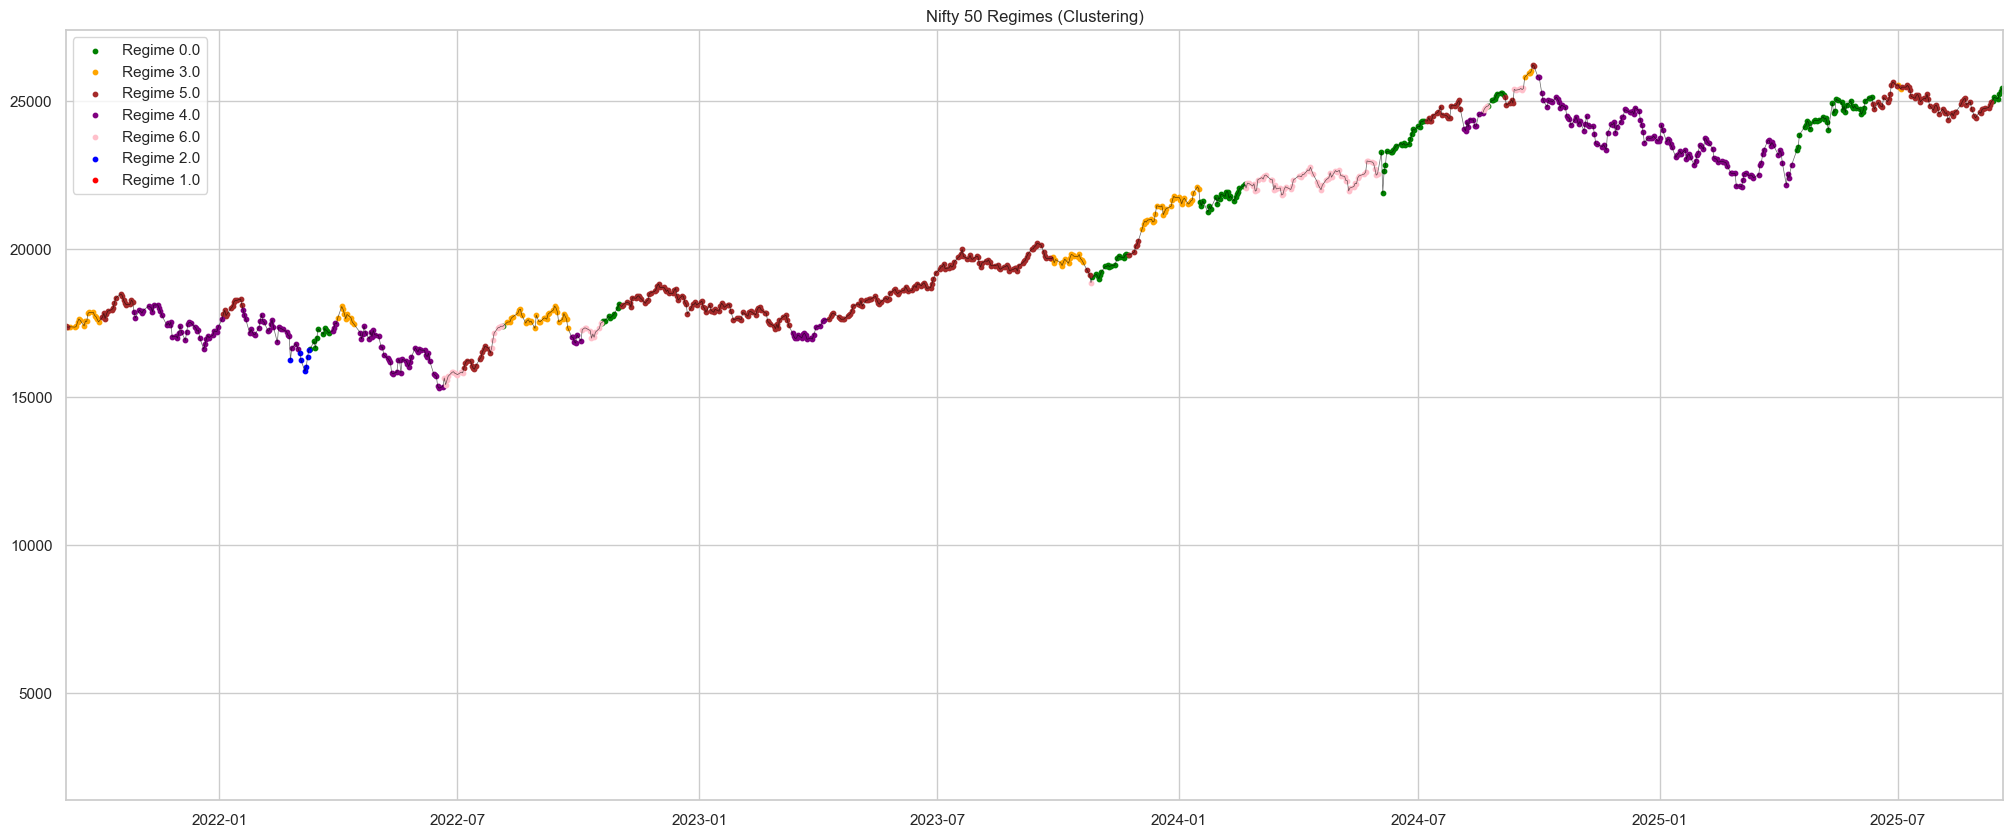

In [60]:
plt.figure(figsize=(25,10))
colors = {0:"green", 1:"red", 2:"blue", 3:"orange", 4:"purple", 5:"brown", 6:"pink", 7:"gray", 8:"cyan", 9:"magenta"}
for c in df_merged['regime_id'].dropna().unique():
    mask = df_merged['regime_id'] == c
    plt.scatter(df_merged.index[mask], df_merged['Close'][mask], label=f"Regime {c}", s=10, c=colors[c])
plt.plot(df_merged.index, df_merged['Close'], color='black', linewidth=0.5, alpha=0.6)
plt.title("Nifty 50 Regimes (Clustering)")
plt.legend()
# show last 1000 days
plt.xlim(df_merged.index[-1000], df_merged.index[-1])
plt.show()

In [36]:
from sklearn.metrics import pairwise_distances

dist = pairwise_distances(kmeans.cluster_centers_)
np.round(dist, 2)

array([[ 0.  , 13.41,  2.56,  4.76,  3.75,  1.73,  2.54],
       [13.41,  0.  , 14.87, 10.7 , 12.17, 14.47, 11.91],
       [ 2.56, 14.87,  0.  ,  6.45,  3.7 ,  2.51,  4.91],
       [ 4.76, 10.7 ,  6.45,  0.  ,  4.33,  5.12,  2.85],
       [ 3.75, 12.17,  3.7 ,  4.33,  0.  ,  4.11,  4.4 ],
       [ 1.73, 14.47,  2.51,  5.12,  4.11,  0.  ,  3.33],
       [ 2.54, 11.91,  4.91,  2.85,  4.4 ,  3.33,  0.  ]])

In [ ]:
import plotly.graph_objects as go



color_dict={0:"green", 1:"red", 2:"blue", 3:"orange", 4:"purple", 5:"brown", 6:"pink", 7:"gray", 8:"cyan", 9:"magenta"}

plot_data = df_merged.dropna(subset=['regime_id']).copy()
plot_data['regime_id'] = plot_data['regime_id'].astype(int)
plot_data['Regime'] = 'Regime ' + plot_data['regime_id'].astype(str)

color_mapping = {f'Regime {k}': v for k, v in color_dict.items()}

# Create the plot
fig = px.scatter(
    plot_data, 
    x=plot_data.index, 
    y='Close',
    color='Regime',
    color_discrete_map=color_mapping,
    title="Nifty 50 Regimes (Clustering)"
)

fig.add_trace(go.Scatter(
    x=df_merged.index,
    y=df_merged['Close'],
    mode='lines',
    line=dict(color='black', width=0.5),
    name='Price Line',
    showlegend=False
))


fig.update_layout(
    height=600,
    xaxis_title="Date",
    yaxis_title="Close Price"
)

fig.show()

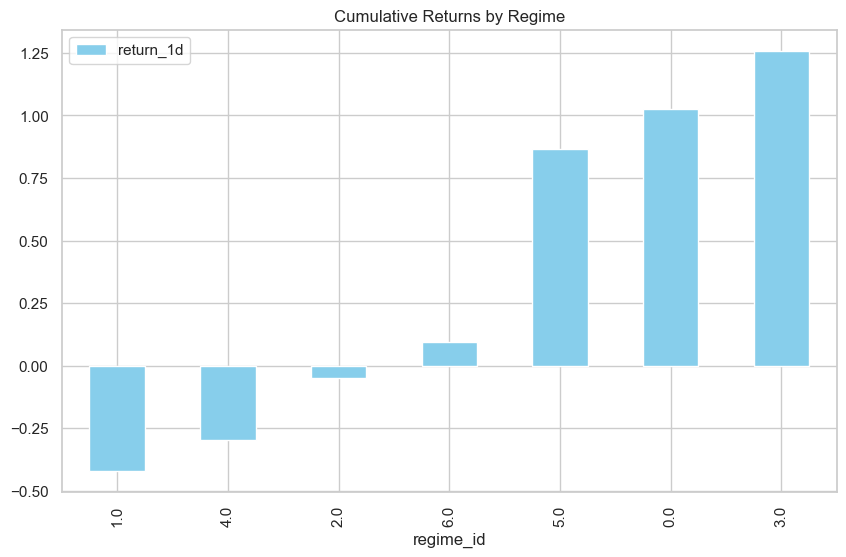

In [83]:
df_merged[["return_1d", "regime_id"]].groupby("regime_id").sum().sort_values(by="return_1d").plot(kind='bar', figsize=(10,6), color='skyblue')
plt.title("Cumulative Returns by Regime");

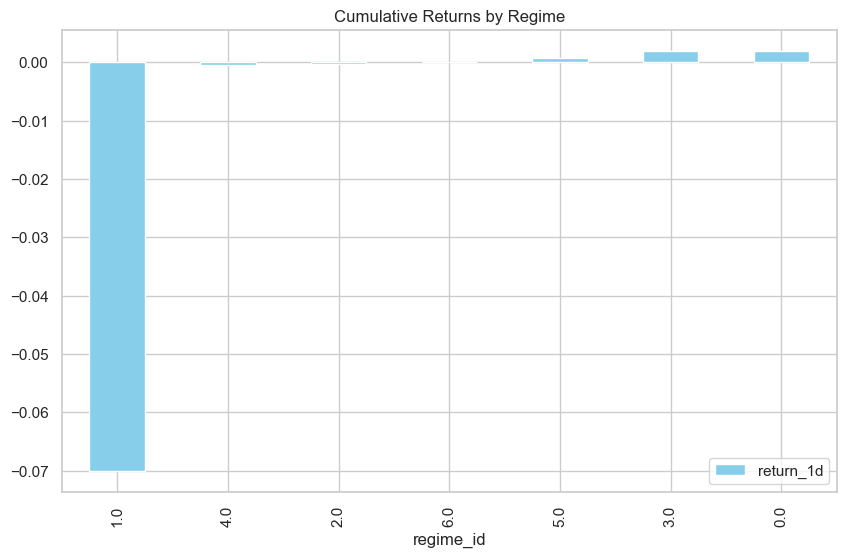

In [85]:
df_merged[["return_1d", "regime_id"]].groupby("regime_id").mean().sort_values(by="return_1d").plot(kind='bar', figsize=(10,6), color='skyblue')
plt.title("Cumulative Returns by Regime");

In [6]:
import yfinance as yf

tcs = yf.Ticker("TCS.NS")

In [9]:
tcs.info

{'address1': 'TCS House',
 'address2': 'Raveline Street Corner of Hazarimal Somani Marg Near Sterling Cinema, Fort',
 'city': 'Mumbai',
 'zip': '400 001',
 'country': 'India',
 'phone': '91 22 6778 9999',
 'fax': '91 22 6778 9000',
 'website': 'https://www.tcs.com',
 'industry': 'Information Technology Services',
 'industryKey': 'information-technology-services',
 'industryDisp': 'Information Technology Services',
 'sector': 'Technology',
 'sectorKey': 'technology',
 'sectorDisp': 'Technology',
 'longBusinessSummary': 'Tata Consultancy Services Limited provides information technology (IT) and IT enabled services in the Americas, Europe, India, and internationally. The company provides TCS ADD, a suite of AI powered life sciences platforms; TCS BaNCS, a financial services platform; TCS BFSI Platforms, a cloud-native, as-a-service digital ecosystem for insurers and financial firms; TCS Chroma, a cloud-based human resource management system platform; TCS Customer Intelligence & Insights, 